# 22 · Transfer Learning, Parameter-Efficient Fine-Tuning and Foundation Models

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/anuxlab/deep-learning-systems/blob/main/notebooks/22-transfer-foundation/22_transfer_foundation.ipynb)
[![Run on GitHub Actions](https://img.shields.io/badge/run-GitHub%20Actions-2088FF?logo=githubactions&logoColor=white)](https://github.com/anuxlab/deep-learning-systems/actions/workflows/nb-22-transfer-foundation.yml)

| | |
|---|---|
| **Wiki chapter** | [Module 22](https://github.com/anuxlab/deep-learning-systems/wiki/Module-22) |
| **Level** | Advanced |
| **Typical CPU runtime** | ~1–2 min (GitHub free runner, no GPU) |
| **Prerequisites** | Modules 07, 10, 16 |

## What you will do

- Pre-train on a *source* task and compare scratch vs frozen-feature vs full fine-tuning on a *target* task across label budgets.
- Measure catastrophic forgetting and mitigate it with EWC (Fisher-weighted penalty) and replay.
- Implement LoRA from scratch: verify zero-init identity, merge equivalence and the parameter saving.
- Build a few-shot prototype classifier on pre-trained embeddings.

> **How to use this notebook.** Read each markdown cell, *predict* what the next code cell will print, then run it.
> Every section ends with `check(...)` assertions: if one fails, something in your understanding (or the code) is off.
> Figures are saved to `figures/` and a machine-readable summary to `metrics.json` next to this notebook.

## 0 · Setup and reproducibility

We import shared helpers (`show` saves each figure to `figures/`, `check` asserts and logs, `timer` logs wall-clock time), fix all random seeds and print an environment report so every run is traceable (see the wiki's *Implementation and Research Standards*).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "_common"))   # shared helpers: notebooks/_common/dlsys.py
from dlsys import *                                       # np, plt, torch, seed_everything, show, check, timer, ...

SEED = seed_everything(42)
ENV = env_report()

18:16:48 | INFO | seed set to 42


          python: 3.12.16
        platform: Linux-7.0.0-1019-azure-x86_64-with-glibc2.43
       cpu_count: 4
          ram_gb: 15.6
           numpy: 2.5.5
           scipy: 1.18.1
         sklearn: 1.9.1
      matplotlib: 3.11.2
           torch: 2.15.0+cpu
  cuda_available: False
  github_actions: True
          run_id: 43926961884
          commit: 30206410b37c093a0d326d94f81e5fd7c94a76ce


## 1 · Setup: a source task and a different target task
Digits dataset (8×8). **Source** = digits 0–4 (plenty of labels). **Target** = digits 5–9 (very few labels). The *same* 10-way output layer is used throughout, so forgetting is measurable later. The pre-trained network is a 3-layer MLP; its penultimate layer provides the **features** to transfer.

In [2]:
from sklearn.datasets import load_digits
D = load_digits(); X = torch.tensor(D.data / 16., dtype=torch.float32); y = torch.tensor(D.target)
idx = np.random.default_rng(0).permutation(len(X)); tr, te = idx[:1300], idx[1300:]
src_tr = tr[y[tr] < 5]; tgt_pool = tr[y[tr] >= 5]; src_te = te[y[te] < 5]; tgt_te = te[y[te] >= 5]
print(f"source train {len(src_tr)}  target pool {len(tgt_pool)}  source test {len(src_te)}  target test {len(tgt_te)}")
class Net(nn.Module):
    def __init__(s, h=128): super().__init__(); s.f = nn.Sequential(nn.Linear(64, h), nn.ReLU(), nn.Linear(h, 64), nn.ReLU()); s.head = nn.Linear(64, 10)
    def forward(s, x): return s.head(s.f(x))
def acc(m, ix):
    m.eval()
    with torch.no_grad(): return (m(X[ix]).argmax(1) == y[ix]).float().mean().item()
def fit(m, ix, epochs=60, lr=3e-3, params=None, extra=None, bs=32, seed=0):
    torch.manual_seed(seed); o = torch.optim.Adam(params if params is not None else m.parameters(), lr); ix = torch.as_tensor(ix)
    for ep in range(epochs):
        m.train(); perm = ix[torch.randperm(len(ix))]
        for s in range(0, len(perm), bs):
            b = perm[s:s + bs]; loss = F.cross_entropy(m(X[b]), y[b]) + (extra(m) if extra else 0); o.zero_grad(); loss.backward(); o.step()
    return m
torch.manual_seed(0); pre = Net(); fit(pre, src_tr, epochs=40)
print(f"pre-trained: source test acc {acc(pre, src_te):.3f}   target test acc (never seen) {acc(pre, tgt_te):.3f}")
check(acc(pre, src_te) > .95, "source task solved"); check(acc(pre, tgt_te) < .05, "target classes are unseen: the pre-trained model scores ≈ 0 on them")

source train 640  target pool 660  source test 261  target test 236


pre-trained: source test acc 0.996   target test acc (never seen) 0.000
  ✅ source task solved
  ✅ target classes are unseen: the pre-trained model scores ≈ 0 on them


## 2 · Scratch vs transfer, across label budgets — and negative transfer
For $n$ labelled examples per target class ($n\in\{1,2,5,10,25,60\}$), averaged over 5 random draws, we compare:

- **scratch** — a new random network trained on the target labels;
- **sup-frozen / sup-finetune** — start from the network *supervised* on source digits 0–4: freeze it and train a fresh linear head, or fine-tune everything;
- **ssl-frozen / ssl-finetune** — start from an encoder pre-trained **without labels** (an autoencoder on *all* training images, i.e. a broad, self-supervised source — the foundation-model recipe).

Theory says transfer helps when source features are *relevant and rich*. A model supervised on only five classes keeps just the information that separates those five (features "collapse" onto 5 directions), so it can actually do **worse than scratch** on new classes — *negative transfer*. Let's see what the numbers say.

autoencoder (self-supervised) reconstruction MSE: 0.0034


scratch       n=1:0.71 n=2:0.74 n=5:0.90 n=10:0.93 n=25:0.97 n=60:0.98
sup-frozen    n=1:0.38 n=2:0.42 n=5:0.53 n=10:0.63 n=25:0.69 n=60:0.73
sup-finetune  n=1:0.46 n=2:0.49 n=5:0.53 n=10:0.67 n=25:0.81 n=60:0.95
ssl-frozen    n=1:0.70 n=2:0.77 n=5:0.91 n=10:0.91 n=25:0.96 n=60:0.97
ssl-finetune  n=1:0.48 n=2:0.57 n=5:0.65 n=10:0.83 n=25:0.93 n=60:0.96


18:17:09 | INFO | figure saved -> figures/transfer_curves.png


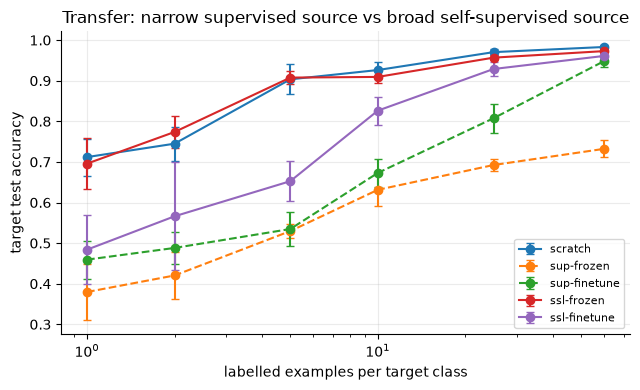

n=5 → scratch 0.903 | sup-frozen 0.530 | ssl-frozen 0.908 | ssl-finetune 0.653
NEGATIVE TRANSFER observed for the narrow supervised source.
  ✅ with many labels the scratch model works well (the gap closes)
  ✅ a broad self-supervised encoder transfers far better than a narrow supervised one (frozen, n=5)
  ✅ …and also at n=1


In [3]:
class AEnc(nn.Module):
    def __init__(s): super().__init__(); s.f = nn.Sequential(nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU()); s.dec = nn.Sequential(nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, 64), nn.Sigmoid())
    def forward(s, x): return s.dec(s.f(x))
torch.manual_seed(0); ae = AEnc(); oa = torch.optim.Adam(ae.parameters(), 3e-3); alltr = torch.as_tensor(tr)      # NOTE: labels are NOT used here
for ep in range(80):
    perm = alltr[torch.randperm(len(alltr))]
    for s_ in range(0, len(perm), 64): b_ = perm[s_:s_ + 64]; l = F.mse_loss(ae(X[b_]), X[b_]); oa.zero_grad(); l.backward(); oa.step()
print(f"autoencoder (self-supervised) reconstruction MSE: {l.item():.4f}")
import copy
def draw(n, seed): r = np.random.default_rng(seed); return np.concatenate([r.choice(tgt_pool[y[tgt_pool] == c], n, replace=False) for c in range(5, 10)])
def run_method(method, n, seed):
    ix = draw(n, seed); torch.manual_seed(seed)
    if method == "scratch": m = Net(); fit(m, ix, epochs=80, seed=seed); return acc(m, tgt_te)
    m = Net(); src_f = pre.f if method.startswith("sup") else ae.f; m.f = copy.deepcopy(src_f); m.head = nn.Linear(64, 10)
    if method.endswith("frozen"): [p.requires_grad_(False) for p in m.f.parameters()]; fit(m, ix, epochs=80, params=m.head.parameters(), lr=1e-2, seed=seed)
    else: fit(m, ix, epochs=40, lr=5e-4, seed=seed)
    return acc(m, tgt_te)
ns = [1, 2, 5, 10, 25, 60]; methods = ["scratch", "sup-frozen", "sup-finetune", "ssl-frozen", "ssl-finetune"]
R = {meth: np.array([[run_method(meth, n, s) for s in range(5)] for n in ns]) for meth in methods}
for meth, a in R.items(): print(f"{meth:13s}", " ".join(f"n={n}:{a[i].mean():.2f}" for i, n in enumerate(ns)))
for meth, a in R.items(): plt.errorbar(ns, a.mean(1), a.std(1), marker="o", capsize=3, label=meth, ls="--" if meth.startswith("sup") else "-")
plt.xscale("log"); plt.xlabel("labelled examples per target class"); plt.ylabel("target test accuracy"); plt.legend(fontsize=8); plt.title("Transfer: narrow supervised source vs broad self-supervised source"); show("transfer_curves")
neg = R["sup-frozen"][2].mean() < R["scratch"][2].mean(); print("n=5 → scratch %.3f | sup-frozen %.3f | ssl-frozen %.3f | ssl-finetune %.3f" % tuple(R[k][2].mean() for k in ["scratch", "sup-frozen", "ssl-frozen", "ssl-finetune"]))
print("NEGATIVE TRANSFER observed for the narrow supervised source." if neg else "No negative transfer observed here.")
check(R["scratch"][-1].mean() > .9, "with many labels the scratch model works well (the gap closes)")
check(R["ssl-frozen"][2].mean() > R["sup-frozen"][2].mean() + .1, "a broad self-supervised encoder transfers far better than a narrow supervised one (frozen, n=5)")
check(R["ssl-frozen"][0].mean() > R["sup-frozen"][0].mean(), "…and also at n=1")
METRICS["transfer"] = {m: dict(zip(map(str, ns), a.mean(1))) for m, a in R.items()}; METRICS["negative_transfer_observed"] = bool(neg)

## 3 · Catastrophic forgetting and EWC
Fine-tuning on the target **overwrites** what the network knew about the source: source accuracy collapses. **Elastic Weight Consolidation** adds a quadratic penalty that anchors important weights:
$$\mathcal L=\mathcal L_{target}+\frac\lambda2\sum_iF_i(\theta_i-\theta^*_i)^2,\qquad F_i=\mathbb E\big[(\partial\log p(y|x;\theta^*)/\partial\theta_i)^2\big]$$
($F$ = diagonal Fisher information on the *source* data, computed with labels **sampled from the model**). We also try **replay** (mix in 5% stored source examples).

Fisher magnitudes: max 8.7e-05, mean 1.4e-06  (tiny because the source model is very confident ⇒ gradients of log p are ≈ 0 ⇒ λ must be large, 1e5–1e6)


plain fine-tune      source acc 0.000   target acc 0.780


EWC λ=1e4            source acc 0.038   target acc 0.784


EWC λ=1e5            source acc 0.464   target acc 0.750


EWC λ=1e6            source acc 0.828   target acc 0.653


replay (60 src ex.)  source acc 0.885   target acc 0.780
18:17:10 | INFO | figure saved -> figures/forgetting_ewc.png


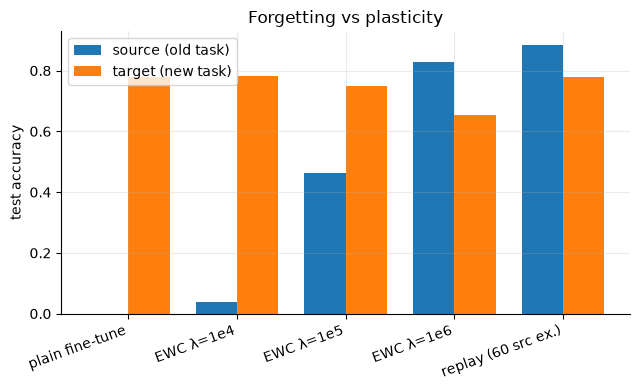

  ✅ plain fine-tuning catastrophically forgets the source task
  ✅ EWC (λ=1e6) retains most of the source task
  ✅ …at some cost in new-task accuracy: the stability–plasticity trade-off
  ✅ a tiny replay buffer also prevents forgetting


In [4]:
def fisher_diag(m, ix, n=400):
    m.eval(); F_ = {k: torch.zeros_like(p) for k, p in m.named_parameters()}; ix = np.random.default_rng(0).choice(ix, n, replace=False)
    for i in ix:
        m.zero_grad(); lp = F.log_softmax(m(X[i:i + 1]), 1); lab = torch.multinomial(lp.exp(), 1).item(); lp[0, lab].backward()
        for k, p in m.named_parameters(): F_[k] += p.grad.detach() ** 2 / n
    return F_
Fish = fisher_diag(pre, src_tr); star = {k: p.detach().clone() for k, p in pre.named_parameters()}
def ewc_pen(lam): return lambda m: lam / 2 * sum((Fish[k] * (p - star[k]) ** 2).sum() for k, p in m.named_parameters())
tgt_ix = draw(40, 0); rep_ix = np.random.default_rng(1).choice(src_tr, 60, replace=False); out = {}
print(f"Fisher magnitudes: max {max(f.max().item() for f in Fish.values()):.1e}, mean {np.mean([f.mean().item() for f in Fish.values()]):.1e}  (tiny because the source model is very confident ⇒ gradients of log p are ≈ 0 ⇒ λ must be large, 1e5–1e6)")
for name, kw in {"plain fine-tune": {}, "EWC λ=1e4": dict(extra=ewc_pen(1e4)), "EWC λ=1e5": dict(extra=ewc_pen(1e5)), "EWC λ=1e6": dict(extra=ewc_pen(1e6)), "replay (60 src ex.)": dict(replay=True)}.items():
    m = copy.deepcopy(pre); ixs = np.concatenate([tgt_ix, rep_ix]) if kw.get("replay") else tgt_ix
    fit(m, ixs, epochs=40, lr=1e-3, extra=kw.get("extra")); out[name] = (acc(m, src_te), acc(m, tgt_te)); print(f"{name:20s} source acc {out[name][0]:.3f}   target acc {out[name][1]:.3f}")
names = list(out); w_ = .38; plt.bar(np.arange(len(names)) - w_ / 2, [out[n][0] for n in names], w_, label="source (old task)"); plt.bar(np.arange(len(names)) + w_ / 2, [out[n][1] for n in names], w_, label="target (new task)")
plt.xticks(range(len(names)), names, rotation=20, ha='right'); plt.ylabel("test accuracy"); plt.legend(); plt.title("Forgetting vs plasticity"); show("forgetting_ewc")
check(out["plain fine-tune"][0] < .3, "plain fine-tuning catastrophically forgets the source task")
check(out["EWC λ=1e6"][0] > out["plain fine-tune"][0] + .5, "EWC (λ=1e6) retains most of the source task")
check(out["EWC λ=1e6"][1] < out["plain fine-tune"][1] + 1e-9, "…at some cost in new-task accuracy: the stability–plasticity trade-off")
check(out["replay (60 src ex.)"][0] > out["plain fine-tune"][0] + .3, "a tiny replay buffer also prevents forgetting")
METRICS["forgetting"] = out

## 4 · LoRA — low-rank adaptation from scratch
Instead of updating $W\in\mathbb R^{d_{out}\times d_{in}}$, freeze it and learn $\Delta W=\frac\alpha r BA$ with $B\in\mathbb R^{d_{out}\times r}$, $A\in\mathbb R^{r\times d_{in}}$, $r\ll d$. $A$ ~ small random, **$B=0$ at init** so the adapted model starts *identical* to the base. Trainable parameters: $r(d_{in}+d_{out})$ instead of $d_{in}d_{out}$. After training, $W'=W+\frac\alpha rBA$ can be **merged** — zero inference overhead.

In [5]:
class LoRALinear(nn.Module):
    def __init__(s, base, r=4, alpha=8): 
        super().__init__(); s.base = base; [p.requires_grad_(False) for p in base.parameters()]; s.A = nn.Parameter(torch.randn(r, base.in_features) * .05); s.B = nn.Parameter(torch.zeros(base.out_features, r)); s.scale = alpha / r
    def forward(s, x): return s.base(x) + s.scale * (x @ s.A.T) @ s.B.T
    def merged(s): m = nn.Linear(s.base.in_features, s.base.out_features); m.weight.data = s.base.weight.data + s.scale * s.B.data @ s.A.data; m.bias.data = s.base.bias.data.clone(); return m
m0 = copy.deepcopy(pre); m0.head = nn.Linear(64, 10); torch.manual_seed(0)
for p in m0.parameters(): p.requires_grad_(False)
x = X[:16]; ref = m0(x).detach()
m0.f[0] = LoRALinear(m0.f[0], r=4); m0.f[2] = LoRALinear(m0.f[2], r=4)
check(torch.allclose(m0(x), ref, atol=1e-6), "B=0 at init: the LoRA-wrapped model is exactly the base model")
for p in m0.head.parameters(): p.requires_grad_(True)
trainable = sum(p.numel() for p in m0.parameters() if p.requires_grad); total = sum(p.numel() for p in m0.parameters()); full = sum(p.numel() for p in pre.parameters())
print(f"trainable params (LoRA r=4 + new head): {trainable:,} of {total:,} total   |  full fine-tune would train {full:,}  ({trainable/full:.1%})")
fit(m0, draw(10, 0), epochs=100, lr=3e-3, params=[p for p in m0.parameters() if p.requires_grad]); lora_acc = acc(m0, tgt_te)
full_ft = np.mean([run_method("sup-finetune", 10, s) for s in range(3)]); frozen_ = np.mean([run_method("sup-frozen", 10, s) for s in range(3)])
m_full = copy.deepcopy(pre); m_full.head = nn.Linear(64, 10); fit(m_full, draw(10, 0), epochs=100, lr=3e-3); full_same = acc(m_full, tgt_te)
print(f"n=10/class target accuracy:  LoRA {lora_acc:.3f} | full fine-tune, SAME schedule {full_same:.3f} | full fine-tune, small-LR schedule {full_ft:.3f} | frozen linear probe {frozen_:.3f}")
print("(Illustrative, single draw: the source here is a narrow supervised model, so all variants start from poor features; LoRA's advantage is parameter-efficiency and stability, not guaranteed accuracy.)")
check(trainable < .4 * full, "LoRA trains a small fraction of the parameters"); check(lora_acc > .3, "LoRA adapts the model to the new classes")
# merge equivalence
y_lora = m0(X[:32]).detach(); m1 = copy.deepcopy(m0); m1.f[0] = m1.f[0].merged(); m1.f[2] = m1.f[2].merged()
check(torch.allclose(m1(X[:32]).detach(), y_lora, atol=1e-5), "merged weights W + (α/r)BA reproduce the adapter model exactly (no inference overhead)")
check(not torch.allclose(m0.f[0].B, torch.zeros_like(m0.f[0].B)), "B moved away from zero during training")
METRICS["lora"] = dict(trainable=trainable, full=full, lora_acc=lora_acc, full_ft_same_schedule=full_same, full_ft_small_lr=full_ft, frozen=frozen_)
d = 4096; r = 8; print(f"for a 4096×4096 projection: full {d*d:,} vs LoRA r=8 {r*2*d:,} parameters  ({r*2*d/(d*d):.2%})")

  ✅ B=0 at init: the LoRA-wrapped model is exactly the base model
trainable params (LoRA r=4 + new head): 2,186 of 18,762 total   |  full fine-tune would train 17,226  (12.7%)


n=10/class target accuracy:  LoRA 0.894 | full fine-tune, SAME schedule 0.886 | full fine-tune, small-LR schedule 0.648 | frozen linear probe 0.609
(Illustrative, single draw: the source here is a narrow supervised model, so all variants start from poor features; LoRA's advantage is parameter-efficiency and stability, not guaranteed accuracy.)
  ✅ LoRA trains a small fraction of the parameters
  ✅ LoRA adapts the model to the new classes
  ✅ merged weights W + (α/r)BA reproduce the adapter model exactly (no inference overhead)
  ✅ B moved away from zero during training
for a 4096×4096 projection: full 16,777,216 vs LoRA r=8 65,536 parameters  (0.39%)


## 5 · Few-shot learning with prototypes
A foundation-model workflow without any gradient steps: embed examples with the pre-trained feature extractor, average the embeddings of each class's few labelled "support" examples to form **prototypes**, and classify queries by the nearest prototype (cosine). Compare embeddings from the supervised source network, the self-supervised autoencoder, a random network and raw pixels, in $k$-shot episodes on the *unseen* target classes.

raw pixels             [0.709 0.819 0.894 0.917]
random network         [0.653 0.751 0.848 0.879]
supervised source features [0.349 0.388 0.461 0.485]
self-supervised (AE) features [0.683 0.795 0.878 0.9  ]
18:17:12 | INFO | figure saved -> figures/few_shot_prototypes.png


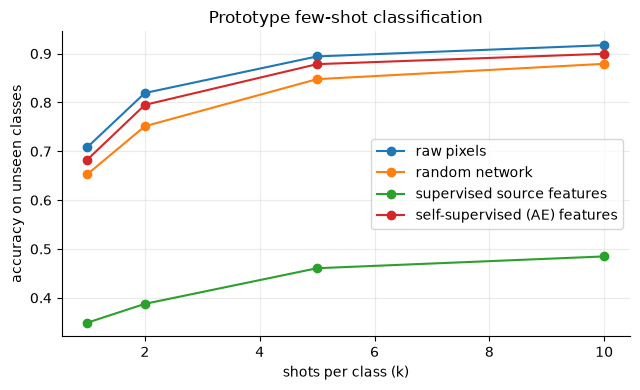

  ✅ 1-shot prototypes classify 5 unseen classes far above chance (20%) with generic features
  ✅ …but features from a narrow supervised source (negative transfer again) are much worse


In [6]:
def embed_fn(kind):
    if kind == "raw pixels": return lambda ix: X[ix]
    if kind == "supervised source features": return lambda ix: pre.f(X[ix]).detach()
    if kind == "self-supervised (AE) features": return lambda ix: ae.f(X[ix]).detach()
    torch.manual_seed(7); rnd = Net(); return lambda ix: rnd.f(X[ix]).detach()
def episodes(kind, k, n_ep=60):
    E = embed_fn(kind); accs = []
    for e in range(n_ep):
        r = np.random.default_rng(e); sup = {c: r.choice(tgt_pool[y[tgt_pool] == c], k, replace=False) for c in range(5, 10)}
        protos = torch.stack([F.normalize(E(sup[c]), dim=1).mean(0) for c in range(5, 10)]); q = F.normalize(E(tgt_te), dim=1); pred = (q @ F.normalize(protos, dim=1).T).argmax(1) + 5; accs.append((pred == y[tgt_te]).float().mean().item())
    return np.mean(accs)
ks = [1, 2, 5, 10]; fs = {kind: [episodes(kind, k) for k in ks] for kind in ["raw pixels", "random network", "supervised source features", "self-supervised (AE) features"]}
for kind, v in fs.items(): plt.plot(ks, v, "o-", label=kind); print(f"{kind:22s}", np.round(v, 3))
plt.xlabel("shots per class (k)"); plt.ylabel("accuracy on unseen classes"); plt.legend(); plt.title("Prototype few-shot classification"); show("few_shot_prototypes")
check(fs["raw pixels"][0] > .5 and fs["self-supervised (AE) features"][0] > .5, "1-shot prototypes classify 5 unseen classes far above chance (20%) with generic features")
check(fs["self-supervised (AE) features"][2] > fs["supervised source features"][2] + .1, "…but features from a narrow supervised source (negative transfer again) are much worse")
METRICS["few_shot"] = fs

In [7]:
save_metrics("22", METRICS)
log.info('notebook 22 finished OK')

18:17:12 | INFO | metrics saved -> metrics.json


18:17:12 | INFO | notebook 22 finished OK


## Wrap-up

## Exercises (do these next)

1. Sweep the LoRA rank r ∈ {1,2,4,8,16} and plot accuracy vs trainable parameters.
2. Replace the Fisher penalty by a plain L2 penalty to the old weights (L2-SP) and compare with EWC.
3. Implement a bottleneck *adapter* module (down-project, ReLU, up-project, residual) and compare with LoRA at equal parameters.

## Where to read more

- Wiki chapter: [Module 22](https://github.com/anuxlab/deep-learning-systems/wiki/Module-22) (derivations, worked example, Q&A).
- Yosinski et al. (2014) *How transferable are features?*; Kirkpatrick et al. (2017) EWC; Hu et al. (2022) LoRA; Houlsby et al. (2019) adapters; Snell et al. (2017) prototypical networks; Bommasani et al. (2021) *On the opportunities and risks of foundation models*.